# Similar Triangles: Seeing the Same Shape

## The intuition

Similar triangles are the same shape at different sizes—like the same photo resized, or the same shape drawn close-up and far away. One triangle may be turned, flipped, or enlarged, but its angles still have the same “corner shape.” Its sides all stretch by one common scale factor.

A useful mental question is not “Which rule should I apply?” but: **Could I shrink, enlarge, rotate, or flip one of these triangles until it sits on top of the other?** If yes, they are similar.

The picture shows a familiar clue: a segment drawn parallel to one side of a triangle makes a small triangle that is a scaled copy of the whole triangle. The parallel direction preserves the corner shapes, while the distances from the shared vertex are reduced by the same factor.

## A way to look for them

When a diagram feels busy, imagine tracing one triangle and sliding it over another. Compare the *shape* of the corners, not the apparent lengths (drawings are not always to scale). Look for a shared corner, a line going in the same direction as another side, or triangles that seem to have the same “tilt.” Then ask whether the remaining corners must match too.

Once the shapes match, side-length ratios are just the zoom amount. For instance, if one triangle is twice as large in every direction, each corresponding side is doubled and its area is four times as large. Similarity is therefore a way to transfer information from a triangle you understand to one you do not.

The formal angle/side tests are useful ways to *confirm* the visual idea; they are not the idea itself.

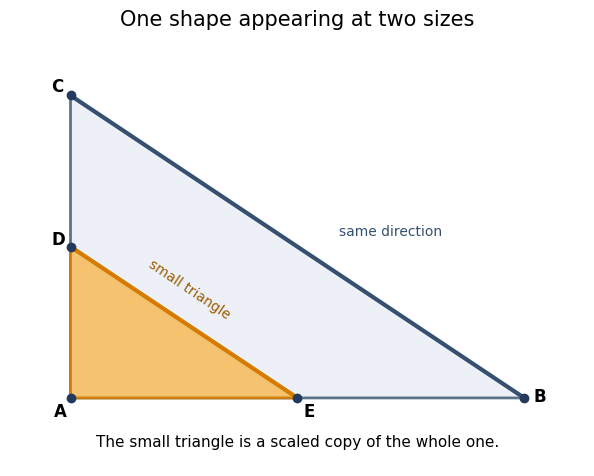

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# A large triangle and a half-size copy formed by a parallel segment.
A = (0, 0)
B = (6, 0)
C = (0, 4)
D = (0, 2)
E = (3, 0)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.add_patch(Polygon([A, B, C], closed=True, facecolor='#e9eef5', edgecolor='#355070', linewidth=2, alpha=0.8))
ax.add_patch(Polygon([A, E, D], closed=True, facecolor='#f6bd60', edgecolor='#d47b00', linewidth=2, alpha=0.9))

# The inner segment DE is parallel to the outer side CB.
ax.plot([D[0], E[0]], [D[1], E[1]], color='#d47b00', linewidth=3)
ax.plot([C[0], B[0]], [C[1], B[1]], color='#355070', linewidth=3)

for point, label, offset in [(A, 'A', (-0.22, -0.25)), (B, 'B', (0.12, -0.05)), (C, 'C', (-0.25, 0.05)), (D, 'D', (-0.25, 0.02)), (E, 'E', (0.08, -0.25))]:
    ax.scatter(*point, color='#23395d', zorder=3)
    ax.text(point[0] + offset[0], point[1] + offset[1], label, fontsize=12, weight='bold')

ax.text(3.55, 2.15, 'same direction', color='#355070', fontsize=10)
ax.text(1.0, 1.05, 'small triangle', color='#9c5c00', fontsize=10, rotation=-34)
ax.text(3.0, -0.65, 'The small triangle is a scaled copy of the whole one.', ha='center', fontsize=11)
ax.set_xlim(-0.8, 6.8)
ax.set_ylim(-0.9, 4.7)
ax.set_aspect('equal', adjustable='box')
ax.axis('off')
ax.set_title('One shape appearing at two sizes', fontsize=15, pad=12)
plt.show()

## Similarity tests—and why they work

The tests are compact ways to check that two triangles really have the same shape. Each gives enough information to fix every corner and every side proportion; the triangles can then differ only by a uniform scale (and possibly a turn or flip).

### 1. AA: two matching angles

If two angles in one triangle match two angles in another, the third angles match automatically: each triangle's angles add to $180^\circ$. So all three corner shapes are the same, which fixes the triangle's shape. The side lengths may differ, but they are all in the same proportion.

This is the most natural test to spot in a diagram: a shared angle plus a pair of parallel lines often gives another equal angle. For example, in the diagram above, $AD$ lies along $AC$, and $DE$ is parallel to $CB$. Those directions preserve the corresponding corner angles, so $\triangle ADE$ is a smaller copy of $\triangle ABC$.

### 2. SAS: two side ratios and the angle between them

If two pairs of corresponding sides have the same ratio, and the angle *between* those sides is equal, then the two sides open out by the same amount and the same shape is formed. Scaling both sides by the same factor while keeping their included angle fixed determines the triangle.

The angle must be the included angle—the corner made by the two sides being compared. Without it, those sides could open by different amounts and make different shapes.

### 3. SSS: all three side ratios match

If all three corresponding side lengths are multiplied by the same factor, the triangles are the same shape at different scales. The side lengths alone determine a triangle's shape (up to turning or flipping), so matching all three ratios is enough.

### A useful picture to keep in mind

AA checks the corners; SAS checks two scaled sides and their opening; SSS checks the whole outline. These are not unrelated tricks—they are three different ways to verify that one triangle could be resized and placed on top of the other.

When using a test, match the vertices in the same order. Once the correspondence is right, matching side ratios follow from the shared shape.

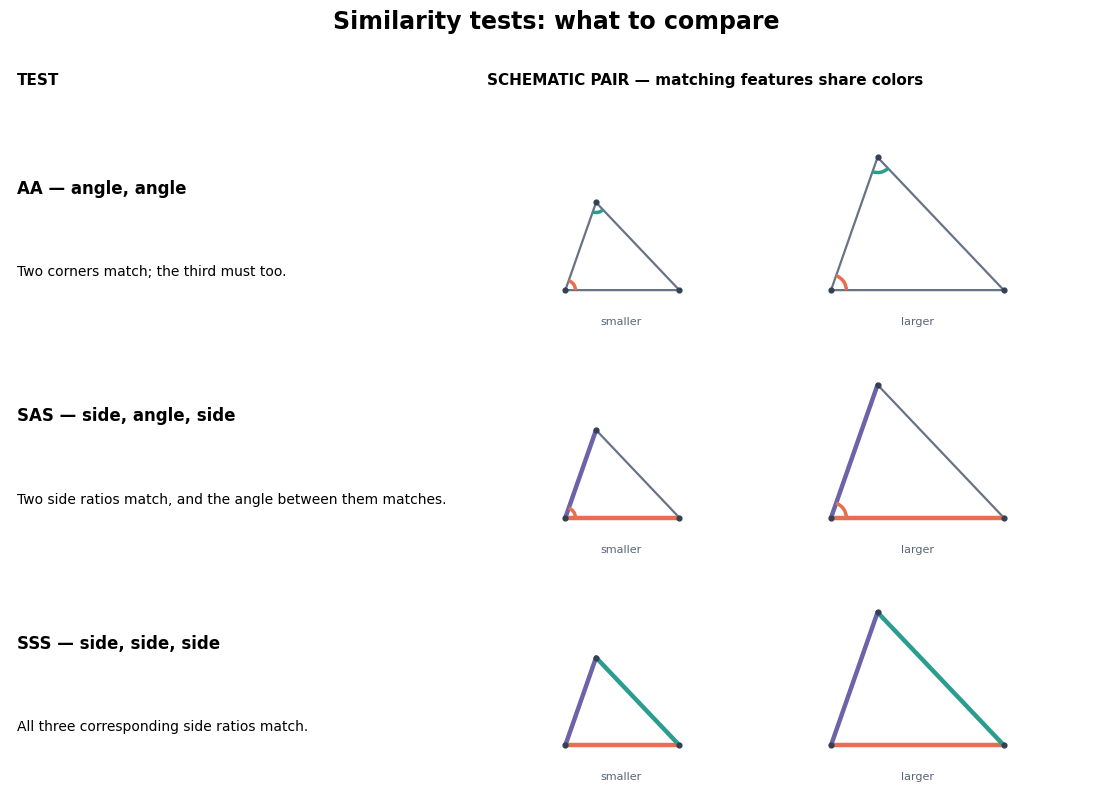

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc

fig, axes = plt.subplots(
    4, 2, figsize=(11, 8),
    gridspec_kw={'height_ratios': [0.35, 1, 1, 1], 'width_ratios': [1.35, 2.5]},
    constrained_layout=True,
 )
fig.suptitle('Similarity tests: what to compare', fontsize=17, weight='bold')

axes[0, 0].text(0.02, 0.5, 'TEST', weight='bold', fontsize=11, va='center')
axes[0, 1].text(0.02, 0.5, 'SCHEMATIC PAIR — matching features share colors', weight='bold', fontsize=11, va='center')
for ax in axes[0]:
    ax.axis('off')

row_text = [
    ('AA — angle, angle', 'Two corners match; the third must too.'),
    ('SAS — side, angle, side', 'Two side ratios match, and the angle between them matches.'),
    ('SSS — side, side, side', 'All three corresponding side ratios match.'),
]
colors = ['#e76f51', '#2a9d8f', '#6c63a8']
base = np.array([[0.0, 0.0], [1.3, 0.0], [0.35, 1.0]])
edge_pairs = [(0, 1), (1, 2), (2, 0)]

def draw_triangle_pair(ax, mode):
    for scale, xshift in [(0.66, 0.0), (1.0, 2.0)]:
        pts = base * scale + np.array([xshift, 0.12])
        closed = np.vstack([pts, pts[0]])
        ax.plot(closed[:, 0], closed[:, 1], color='#687386', lw=1.6, zorder=1)

        if mode == 'SSS':
            highlighted = [0, 1, 2]
        elif mode == 'SAS':
            highlighted = [0, 2]  # the two sides meeting at vertex 0
        else:
            highlighted = []

        for edge_id in highlighted:
            i, j = edge_pairs[edge_id]
            ax.plot(pts[[i, j], 0], pts[[i, j], 1], color=colors[edge_id], lw=3.2, solid_capstyle='round', zorder=2)

        if mode in ('AA', 'SAS'):
            vertices = [0, 2] if mode == 'AA' else [0]
            for mark_id, vertex_id in enumerate(vertices):
                others = [j for j in range(3) if j != vertex_id]
                rays = [np.degrees(np.arctan2(*(pts[j] - pts[vertex_id])[::-1])) for j in others]
                theta1, theta2 = sorted(rays)
                if theta2 - theta1 > 180:
                    theta1, theta2 = theta2, theta1 + 360
                radius = 0.23 * scale
                ax.add_patch(Arc(pts[vertex_id], radius, radius, theta1=theta1, theta2=theta2, color=colors[mark_id], lw=2.5, zorder=3))

        ax.scatter(pts[:, 0], pts[:, 1], s=12, color='#344054', zorder=4)

    ax.text(0.42, -0.08, 'smaller', ha='center', va='top', fontsize=8, color='#596579')
    ax.text(2.65, -0.08, 'larger', ha='center', va='top', fontsize=8, color='#596579')
    ax.set_xlim(-0.2, 3.55)
    ax.set_ylim(-0.3, 1.35)
    ax.set_aspect('equal')
    ax.axis('off')

for row, (title, explanation) in enumerate(row_text, start=1):
    left, right = axes[row]
    left.axis('off')
    left.text(0.02, 0.72, title, fontsize=12, weight='bold', va='center')
    left.text(0.02, 0.34, explanation, fontsize=10, va='center', wrap=True)
    right.axis('off')
    draw_triangle_pair(right, title[:3].strip())

plt.show()